In [ ]:
EXTEND_TO_FULL_MSMARCO = True  # set True to process full MS MARCO dev


# MS MARCO Re-annotation Pipeline

## Цель
1. Обучить судью (Cross-Encoder) на 1179 доразмеченных запросах
2. Применить судью для расширения разметки на весь MS MARCO dev-set (6980 запросов)
3. Сравнить NDCG метрики для BM25, E5, BGE, E5-rerank

## Особенности
- NDCG корректно обрабатывает запросы с < k документов
- Threshold подбирается на validation (не на test)
- Judge vs Human оценка только на hold-out
- pseudo_qrels = предсказания судьи
- Явная маркировка pooled-NDCG

---
## 1. Установка и импорты

In [ ]:
# Установка пакетов
!pip install -q pandas numpy scikit-learn tqdm
!pip install -q torch sentence-transformers accelerate
!pip install -q matplotlib seaborn datasets
# Пакеты для полного MS MARCO / Pyserini
!pip install -q 'spacy==3.7.4' 'pyserini==0.22.1' 'ir_datasets==0.5.11' faiss-cpu



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip


In [ ]:
# Ensure flag defined even if earlier cell not run
try:
    EXTEND_TO_FULL_MSMARCO
except NameError:
    EXTEND_TO_FULL_MSMARCO = True

import json
import os
from pathlib import Path
import pandas as pd
import numpy as np
from collections import defaultdict
from typing import Dict, List, Tuple, Optional
import warnings
warnings.filterwarnings('ignore')

import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"MPS available: {torch.backends.mps.is_available()}")

device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device != 'cuda':
    raise RuntimeError('CUDA-required run: set GPU runtime')
print(f"\nUsing device: {device}")

PyTorch version: 2.10.0
CUDA available: False
MPS available: True

Using device: mps


---
## 2. Конфигурация

In [ ]:
class Config:
    # Пути
    DATA_DIR = Path("data_extracted")
    OUTPUT_DIR = Path("output_fixed")
    MODEL_DIR = Path("cross_encoder_finetuned_v2")
    
    # Модель
    BASE_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
    MAX_LENGTH = 512
    
    # Обучение
    TRAIN_RATIO = 0.7
    VAL_RATIO = 0.15
    TEST_RATIO = 0.15
    BATCH_SIZE = 16
    NUM_EPOCHS = 2
    WARMUP_STEPS = 100
    
    # Оценка
    K_VALUES = [1, 5, 10]
    N_BOOTSTRAP = 10000
    N_PERMUTATIONS = 5000
    RANDOM_SEED = 42

config = Config()
config.OUTPUT_DIR.mkdir(exist_ok=True)
np.random.seed(config.RANDOM_SEED)

print(f"Output: {config.OUTPUT_DIR}/")
print(f"Model: {config.BASE_MODEL}")
print(f"   НЕ сравнимо с full-corpus leaderboard!")

Output: output_fixed/
Model: cross-encoder/ms-marco-MiniLM-L-6-v2

⚠️  ВАЖНО: Все NDCG — POOLED (~30-40 док/запрос)
   НЕ сравнимо с full-corpus leaderboard!


In [ ]:
# Параметры полного MS MARCO
from pathlib import Path
MSMARCO_DIR = Path('datasets/msmarco')
MSMARCO_DIR.mkdir(parents=True, exist_ok=True)
TOP_K_PER_MODEL = 200  # сколько документов брать из каждого run


---
## 3. Загрузка данных

In [ ]:
def load_all_labeled_data(data_dir: Path) -> dict:
    """Загружает все JSON файлы с доразмеченными данными"""
    all_data = {}
    json_files = list(data_dir.glob("*.json"))
    
    print(f"Найдено {len(json_files)} JSON файлов:")
    for f in sorted(json_files):
        with open(f, 'r', encoding='utf-8') as file:
            data = json.load(file)
        print(f"  {f.name}: {len(data)} запросов")
        all_data.update(data)
    
    return all_data

labeled_data = load_all_labeled_data(config.DATA_DIR)
print(f"\nВСЕГО: {len(labeled_data)} запросов с доразметкой")

Найдено 12 JSON файлов:
  100 вопросов_M.json: 92 запросов
  next10_вопросы.json: 115 запросов
  next11_вопросы.json: 50 запросов
  next1_вопросы.json: 104 запросов
  next2_вопросы.json: 103 запросов
  next3_вопросы.json: 105 запросов
  next4_вопросы.json: 99 запросов
  next5_вопросы.json: 116 запросов
  next6_вопросы.json: 101 запросов
  next7_вопросы.json: 95 запросов
  next8_вопросы.json: 98 запросов
  next9_вопросы.json: 101 запросов

ВСЕГО: 1179 запросов с доразметкой


In [ ]:
def analyze_labeled_data(data: dict) -> dict:
    """Анализирует статистику по доразмеченным данным"""
    stats = {
        'total_queries': 0,
        'total_docs': 0,
        'label_0': 0,
        'label_1': 0,
        'label_2': 0,
        'docs_per_query': [],
        'relevant_per_query_orig': [],
        'relevant_per_query_new': [],
        'models': defaultdict(int)
    }
    
    for qid, qinfo in data.items():
        stats['total_queries'] += 1
        docs = qinfo['documents']
        stats['total_docs'] += len(docs)
        stats['docs_per_query'].append(len(docs))
        
        rel_orig = 0
        rel_new = 0
        
        for docid, dinfo in docs.items():
            label = dinfo.get('true relevant', 0)
            
            if label == 0:
                stats['label_0'] += 1
            elif label == 1:
                stats['label_1'] += 1
                rel_orig += 1
                rel_new += 1
            elif label == 2:
                stats['label_2'] += 1
                rel_new += 1
            
            for model in dinfo.get('systems', {}).keys():
                stats['models'][model] += 1
        
        stats['relevant_per_query_orig'].append(rel_orig)
        stats['relevant_per_query_new'].append(rel_new)
    
    return stats

stats = analyze_labeled_data(labeled_data)

print("=" * 50)
print("СТАТИСТИКА ДОРАЗМЕЧЕННЫХ ДАННЫХ")
print("=" * 50)
print(f"Всего запросов: {stats['total_queries']}")
print(f"Всего пар (query, doc): {stats['total_docs']}")
print(f"\nРаспределение меток:")
print(f"  Label 0 (не релевант): {stats['label_0']} ({100*stats['label_0']/stats['total_docs']:.1f}%)")
print(f"  Label 1 (оригинал):    {stats['label_1']} ({100*stats['label_1']/stats['total_docs']:.1f}%)")
print(f"  Label 2 (доразметка):  {stats['label_2']} ({100*stats['label_2']/stats['total_docs']:.1f}%)")
print(f"\nДокументов на запрос: {np.mean(stats['docs_per_query']):.1f} (min={min(stats['docs_per_query'])}, max={max(stats['docs_per_query'])})")
print(f"\nРелевантных на запрос:")
print(f"  До доразметки:  {np.mean(stats['relevant_per_query_orig']):.2f}")
print(f"  После:          {np.mean(stats['relevant_per_query_new']):.2f}")

СТАТИСТИКА ДОРАЗМЕЧЕННЫХ ДАННЫХ
Всего запросов: 1179
Всего пар (query, doc): 33667

Распределение меток:
  Label 0 (не релевант): 13041 (38.7%)
  Label 1 (оригинал):    1257 (3.7%)
  Label 2 (доразметка):  19340 (57.4%)

Документов на запрос: 28.6 (min=13, max=63)

Релевантных на запрос:
  До доразметки:  1.07
  После:          17.47


### Визуализация данных

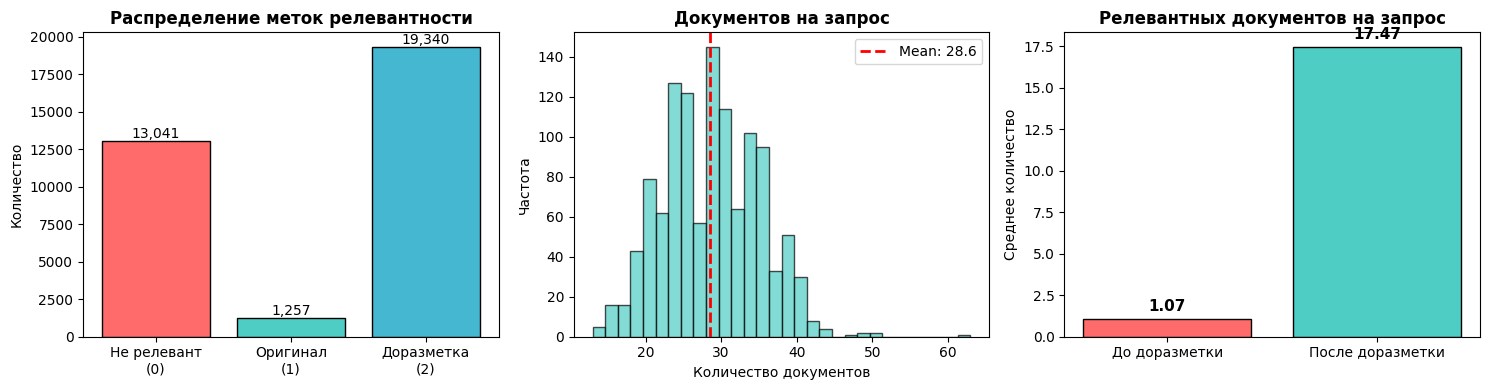

Сохранено: output_fixed/data_statistics.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Распределение меток
labels = ['Не релевант\n(0)', 'Оригинал\n(1)', 'Доразметка\n(2)']
values = [stats['label_0'], stats['label_1'], stats['label_2']]
colors = ['#ff6b6b', '#4ecdc4', '#45b7d1']
bars1 = axes[0].bar(labels, values, color=colors, edgecolor='black')
axes[0].set_title('Распределение меток релевантности', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Количество')
for bar, val in zip(bars1, values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
                 f'{val:,}', ha='center', fontsize=10)

# 2. Документов на запрос
axes[1].hist(stats['docs_per_query'], bins=30, color='#4ecdc4', edgecolor='black', alpha=0.7)
axes[1].axvline(np.mean(stats['docs_per_query']), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {np.mean(stats["docs_per_query"]):.1f}')
axes[1].set_title('Документов на запрос', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Количество документов')
axes[1].set_ylabel('Частота')
axes[1].legend()

# 3. Релевантных до/после
vals = [np.mean(stats['relevant_per_query_orig']), np.mean(stats['relevant_per_query_new'])]
bars3 = axes[2].bar(['До доразметки', 'После доразметки'], vals, 
                    color=['#ff6b6b', '#4ecdc4'], edgecolor='black')
axes[2].set_title('Релевантных документов на запрос', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Среднее количество')
for bar, val in zip(bars3, vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                 f'{val:.2f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(config.OUTPUT_DIR / 'data_statistics.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Сохранено: {config.OUTPUT_DIR / 'data_statistics.png'}")

---
## 4. Подготовка данных для обучения

In [ ]:
def create_training_dataset(data: dict) -> pd.DataFrame:
    """Создает датасет для обучения судьи"""
    samples = []
    
    for qid, qinfo in data.items():
        query_text = qinfo['query_text']
        
        for docid, dinfo in qinfo['documents'].items():
            doc_text = dinfo['text']
            true_rel = dinfo.get('true relevant', 0)
            label = 1 if true_rel in [1, 2] else 0
            systems = dinfo.get('systems', {})
            
            samples.append({
                'qid': qid,
                'docid': docid,
                'query': query_text,
                'document': doc_text,
                'label': label,
                'original_label': true_rel,
                'e5_score': systems.get('e5', np.nan),
                'bm25_score': systems.get('bm25', np.nan),
                'bge_score': systems.get('bge', np.nan),
            })
    
    return pd.DataFrame(samples)

df_full = create_training_dataset(labeled_data)
print(f"Датасет: {len(df_full)} пар")
print(f"Баланс классов: {df_full['label'].mean()*100:.1f}% положительных")

Датасет: 33667 пар
Баланс классов: 61.2% положительных


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

def split_by_queries(df: pd.DataFrame, config):
    """Разбивает данные на train/val/test ПО ЗАПРОСАМ"""
    
    gss1 = GroupShuffleSplit(n_splits=1, test_size=(config.VAL_RATIO + config.TEST_RATIO),
                              random_state=config.RANDOM_SEED)
    train_idx, temp_idx = next(gss1.split(df, groups=df['qid']))
    
    df_train = df.iloc[train_idx].copy()
    df_temp = df.iloc[temp_idx].copy()
    
    val_fraction = config.VAL_RATIO / (config.VAL_RATIO + config.TEST_RATIO)
    gss2 = GroupShuffleSplit(n_splits=1, test_size=(1 - val_fraction),
                              random_state=config.RANDOM_SEED)
    val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp['qid']))
    
    df_val = df_temp.iloc[val_idx].copy()
    df_test = df_temp.iloc[test_idx].copy()
    
    return df_train, df_val, df_test

df_train, df_val, df_test = split_by_queries(df_full, config)

print(f"Разбиение (по запросам):")
print(f"  Train: {len(df_train)} пар ({df_train['qid'].nunique()} запросов)")
print(f"  Val:   {len(df_val)} пар ({df_val['qid'].nunique()} запросов)")
print(f"  Test:  {len(df_test)} пар ({df_test['qid'].nunique()} запросов)")

holdout_qids = set(df_test['qid'].unique())
print(f"\nHold-out запросы: {len(holdout_qids)} qids")

Разбиение (по запросам):
  Train: 23543 пар (825 запросов)
  Val:   5122 пар (177 запросов)
  Test:  5002 пар (177 запросов)

Hold-out запросы: 177 qids


---
## 5. Обучение Cross-Encoder

In [ ]:
from sentence_transformers import CrossEncoder
from sklearn.metrics import (classification_report, roc_auc_score,
                             precision_recall_curve, f1_score, accuracy_score)

def evaluate_cross_encoder(model, df, threshold=None, batch_size=64):
    """Оценивает cross-encoder"""
    pairs = list(zip(df['query'].tolist(), df['document'].tolist()))
    scores = model.predict(pairs, batch_size=batch_size, show_progress_bar=True)
    y_true = df['label'].values
    
    auc = roc_auc_score(y_true, scores)
    
    if threshold is None:
        prec, rec, thresholds = precision_recall_curve(y_true, scores)
        f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
        best_idx = np.argmax(f1_scores)
        threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    
    y_pred = (scores >= threshold).astype(int)
    
    return {
        'scores': scores,
        'auc': auc,
        'threshold': threshold,
        'f1': f1_score(y_true, y_pred),
        'accuracy': accuracy_score(y_true, y_pred),
        'y_pred': y_pred,
        'y_true': y_true
    }

In [ ]:
# Оценка базовой модели
print("Загрузка базовой модели...")
base_model = CrossEncoder(config.BASE_MODEL, device=device, max_length=config.MAX_LENGTH)

base_val_results = evaluate_cross_encoder(base_model, df_val, batch_size=config.BATCH_SIZE)
print(f"\nБазовая модель (validation):")
print(f"  AUC: {base_val_results['auc']:.4f}")
print(f"  F1:  {base_val_results['f1']:.4f}")

Загрузка базовой модели...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/105 [00:00<00:00, 4848.91it/s, Materializing param=bert.embeddings.LayerNorm.bias]

Loading weights:   1%|          | 1/105 [00:00<00:00, 649.68it/s, Materializing param=bert.embeddings.LayerNorm.bias] 

Loading weights:   2%|▏         | 2/105 [00:00<00:00, 713.74it/s, Materializing param=bert.embeddings.LayerNorm.weight]

...

Batches:  98%|█████████▊| 314/321 [00:14<00:00, 28.32it/s]

Batches:  99%|█████████▉| 318/321 [00:15<00:00, 28.38it/s]

Batches: 100%|██████████| 321/321 [00:15<00:00, 25.44it/s]

Batches: 100%|██████████| 321/321 [00:15<00:00, 21.12it/s]


Базовая модель (validation):
  AUC: 0.8648
  F1:  0.8350


In [ ]:
from sentence_transformers.cross_encoder import CrossEncoderTrainer, CrossEncoderTrainingArguments
from datasets import Dataset

FINETUNE = True  # False чтобы пропустить обучение и загрузить сохраненную модель

if FINETUNE:
    print("Подготовка данных для дообучения...")
    
    train_dataset = Dataset.from_dict({
        'sentence1': df_train['query'].tolist(),
        'sentence2': df_train['document'].tolist(),
        'label': df_train['label'].astype(float).tolist()
    })
    
    val_dataset = Dataset.from_dict({
        'sentence1': df_val['query'].tolist(),
        'sentence2': df_val['document'].tolist(),
        'label': df_val['label'].astype(float).tolist()
    })
    
    print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}")
    
    model = CrossEncoder(config.BASE_MODEL, device=device, max_length=config.MAX_LENGTH)
    
    training_args = CrossEncoderTrainingArguments(
        output_dir=str(config.MODEL_DIR),
        num_train_epochs=config.NUM_EPOCHS,
        per_device_train_batch_size=config.BATCH_SIZE,
        per_device_eval_batch_size=config.BATCH_SIZE,
        warmup_steps=config.WARMUP_STEPS,
        logging_steps=500,
        save_strategy='epoch',
        eval_strategy='epoch',
        load_best_model_at_end=True,
        fp16=True,
    )
    
    trainer = CrossEncoderTrainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
    )
    
    print("\nДообучение модели...")
    trainer.train()
    model.save(str(config.MODEL_DIR))
    print(f"Модель сохранена: {config.MODEL_DIR}")
else:
    print("Загрузка сохраненной модели...")
    model = CrossEncoder(str(config.MODEL_DIR), device=device)

Загрузка сохраненной модели...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   1%|          | 1/105 [00:00<00:00, 55188.21it/s, Materializing param=bert.embeddings.LayerNorm.bias]

Loading weights:   1%|          | 1/105 [00:00<00:00, 1565.04it/s, Materializing param=bert.embeddings.LayerNorm.bias] 

Loading weights:   2%|▏         | 2/105 [00:00<00:00, 2041.02it/s, Materializing param=bert.embeddings.LayerNorm.weight]

...

Loading weights:  99%|█████████▉| 104/105 [00:00<00:00, 1153.35it/s, Materializing param=classifier.bias]         

Loading weights:  99%|█████████▉| 104/105 [00:00<00:00, 1151.33it/s, Materializing param=classifier.bias]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1160.16it/s, Materializing param=classifier.weight]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1158.10it/s, Materializing param=classifier.weight]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1155.65it/s, Materializing param=classifier.weight]

In [ ]:
# Подбор threshold на VALIDATION
print("Подбор threshold на validation...")
val_results = evaluate_cross_encoder(model, df_val, threshold=None, batch_size=config.BATCH_SIZE)

optimal_threshold = val_results['threshold']
print(f"Optimal threshold: {optimal_threshold:.4f}")
print(f"Val AUC: {val_results['auc']:.4f}")
print(f"Val F1:  {val_results['f1']:.4f}")

# Оценка на TEST с фиксированным threshold
print("\nОценка на test (с threshold из validation)...")
test_results = evaluate_cross_encoder(model, df_test, threshold=optimal_threshold, batch_size=config.BATCH_SIZE)

print(f"\n{'='*50}")
print("РЕЗУЛЬТАТЫ НА TEST")
print(f"{'='*50}")
print(f"Test AUC: {test_results['auc']:.4f}")
print(f"Test F1:  {test_results['f1']:.4f}")
print(f"Test Acc: {test_results['accuracy']:.4f}")
print(f"\nClassification Report:")
print(classification_report(test_results['y_true'], test_results['y_pred'],
                           target_names=['Not Relevant', 'Relevant']))

Подбор threshold на validation...


Batches:   0%|          | 0/321 [00:00<?, ?it/s]

Batches:   1%|          | 3/321 [00:00<00:10, 29.52it/s]

Batches:   2%|▏         | 6/321 [00:00<00:10, 29.04it/s]

Batches:   3%|▎         | 9/321 [00:00<00:11, 26.73it/s]

...

Batches:  98%|█████████▊| 307/313 [00:11<00:00, 25.51it/s]

Batches:  99%|█████████▉| 310/313 [00:11<00:00, 26.53it/s]

Batches: 100%|██████████| 313/313 [00:11<00:00, 24.30it/s]

Batches: 100%|██████████| 313/313 [00:11<00:00, 27.13it/s]


РЕЗУЛЬТАТЫ НА TEST
Test AUC: 0.9057
Test F1:  0.8745
Test Acc: 0.8335

Classification Report:
              precision    recall  f1-score   support

Not Relevant       0.81      0.70      0.75      1806
    Relevant       0.84      0.91      0.87      3196

    accuracy                           0.83      5002
   macro avg       0.83      0.80      0.81      5002
weighted avg       0.83      0.83      0.83      5002



In [ ]:
# Сохранение конфига судьи
judge_config = {
    'model_name': config.BASE_MODEL,
    'finetuned': True,
    'model_path': str(config.MODEL_DIR),
    'threshold': float(optimal_threshold),
    'threshold_source': 'validation_set',
    'validation_metrics': {
        'auc': float(val_results['auc']),
        'f1': float(val_results['f1']),
        'accuracy': float(val_results['accuracy'])
    },
    'test_metrics': {
        'auc': float(test_results['auc']),
        'f1': float(test_results['f1']),
        'accuracy': float(test_results['accuracy'])
    },
    'base_model_val_auc': float(base_val_results['auc']),
    'improvement': float(val_results['auc'] - base_val_results['auc'])
}

with open(config.OUTPUT_DIR / 'judge_config.json', 'w') as f:
    json.dump(judge_config, f, indent=2)

print("Конфиг сохранен:", config.OUTPUT_DIR / 'judge_config.json')
print(json.dumps(judge_config, indent=2))

Конфиг сохранен: output_fixed/judge_config.json
{
  "model_name": "cross-encoder/ms-marco-MiniLM-L-6-v2",
  "finetuned": true,
  "model_path": "cross_encoder_finetuned_v2",
  "threshold": -0.9439531564712524,
  "threshold_source": "validation_set",
  "validation_metrics": {
    "auc": 0.9035862549129348,
    "f1": 0.8652592362620304,
    "accuracy": 0.8305349472862164
  },
  "test_metrics": {
    "auc": 0.9056829065124317,
    "f1": 0.8744914871176737,
    "accuracy": 0.8334666133546581
  },
  "base_model_val_auc": 0.8647676169019956,
  "improvement": 0.03881863801093921
}


---
## 6. Применение судьи ко всем данным

In [ ]:
import time
from tqdm import tqdm

print("Применение судьи ко всем парам...")

all_pairs = []
all_pair_info = []

for qid, qinfo in labeled_data.items():
    query_text = qinfo['query_text']
    for docid, dinfo in qinfo['documents'].items():
        doc_text = dinfo['text']
        all_pairs.append((query_text, doc_text))
        all_pair_info.append((qid, docid))

print(f"Всего пар: {len(all_pairs):,}")

start_time = time.time()
all_judge_scores = model.predict(all_pairs, batch_size=128, show_progress_bar=True)
elapsed = time.time() - start_time
print(f"Время: {elapsed:.1f} сек ({len(all_pairs)/elapsed:.0f} пар/сек)")

# Создаем словарь предсказаний
judge_predictions = {}
for (qid, docid), score in zip(all_pair_info, all_judge_scores):
    if qid not in judge_predictions:
        judge_predictions[qid] = {}
    judge_predictions[qid][docid] = float(score)

Применение судьи ко всем парам...
Всего пар: 33,667


Batches:   0%|          | 0/264 [00:00<?, ?it/s]

Batches:   1%|          | 2/264 [00:00<01:32,  2.84it/s]

Batches:   1%|          | 3/264 [00:00<01:22,  3.16it/s]

Batches:   2%|▏         | 4/264 [00:01<01:20,  3.22it/s]

...

Batches:  99%|█████████▉| 262/264 [02:45<00:00,  2.00it/s]

Batches: 100%|█████████▉| 263/264 [02:46<00:00,  2.24it/s]

Batches: 100%|██████████| 264/264 [02:46<00:00,  2.31it/s]

Batches: 100%|██████████| 264/264 [02:46<00:00,  1.59it/s]

Время: 172.8 сек (195 пар/сек)


---
## 7. Формирование qrels

In [ ]:
def create_qrels_original(data: dict) -> dict:
    """Qrels из оригинальной разметки MS MARCO (только label=1)"""
    qrels = {}
    for qid, qinfo in data.items():
        qrels[qid] = {}
        for docid, dinfo in qinfo['documents'].items():
            if dinfo.get('true relevant', 0) == 1:
                qrels[qid][docid] = 1
    return qrels


def create_qrels_human(data: dict) -> dict:
    """Qrels из ручной доразметки (label=1 и label=2)"""
    qrels = {}
    for qid, qinfo in data.items():
        qrels[qid] = {}
        for docid, dinfo in qinfo['documents'].items():
            if dinfo.get('true relevant', 0) in [1, 2]:
                qrels[qid][docid] = 1
    return qrels


def create_qrels_judge(data: dict, judge_predictions: dict, threshold: float) -> dict:
    """Qrels из предсказаний судьи"""
    qrels = {}
    for qid, qinfo in data.items():
        qrels[qid] = {}
        if qid not in judge_predictions:
            continue
        for docid in qinfo['documents'].keys():
            if docid in judge_predictions[qid]:
                if judge_predictions[qid][docid] >= threshold:
                    qrels[qid][docid] = 1
    return qrels


qrels_original = create_qrels_original(labeled_data)
qrels_human = create_qrels_human(labeled_data)
qrels_judge = create_qrels_judge(labeled_data, judge_predictions, optimal_threshold)

def count_qrels(qrels):
    total = sum(len(docs) for docs in qrels.values())
    queries = sum(1 for docs in qrels.values() if len(docs) > 0)
    return total, queries

orig_rel, orig_q = count_qrels(qrels_original)
human_rel, human_q = count_qrels(qrels_human)
judge_rel, judge_q = count_qrels(qrels_judge)

print(f"{'Тип':<12} {'Релевантных':<15} {'Запросов':<12} {'Avg/query'}")
print("-"*50)
print(f"{'Original':<12} {orig_rel:<15} {orig_q:<12} {orig_rel/max(orig_q,1):.2f}")
print(f"{'Human':<12} {human_rel:<15} {human_q:<12} {human_rel/max(human_q,1):.2f}")
print(f"{'Judge':<12} {judge_rel:<15} {judge_q:<12} {judge_rel/max(judge_q,1):.2f}")

Тип          Релевантных     Запросов     Avg/query
--------------------------------------------------
Original     1257            1179         1.07
Human        20597           1179         17.47
Judge        22395           1176         19.04


In [ ]:
# Сохранение qrels и скоров

with open(config.OUTPUT_DIR / 'human_qrels_extended.json', 'w') as f:
    json.dump(qrels_human, f)

with open(config.OUTPUT_DIR / 'pseudo_qrels_judge.json', 'w') as f:
    json.dump(qrels_judge, f)

with open(config.OUTPUT_DIR / 'judge_scores_raw.json', 'w') as f:
    json.dump(judge_predictions, f)

# TSV формат
def save_qrels_tsv(qrels, path):
    rows = []
    for qid, docs in qrels.items():
        for docid, rel in docs.items():
            rows.append(f"{qid}\t{docid}\t{rel}")
    with open(path, 'w') as f:
        f.write("query-id\tcorpus-id\tscore\n")
        f.write("\n".join(rows))

save_qrels_tsv(qrels_human, config.OUTPUT_DIR / 'human_qrels_extended.tsv')
save_qrels_tsv(qrels_judge, config.OUTPUT_DIR / 'pseudo_qrels_judge.tsv')

# TSV для сырых скоров
rows = []
for qid, docs in judge_predictions.items():
    for docid, score in docs.items():
        rows.append(f"{qid}\t{docid}\t{score:.6f}")
with open(config.OUTPUT_DIR / 'judge_scores_raw.tsv', 'w') as f:
    f.write("query-id\tcorpus-id\traw-score\n")
    f.write("\n".join(rows))

print("Qrels сохранены:")
print(f"  human_qrels_extended.json/tsv")
print(f"  pseudo_qrels_judge.json/tsv")
print(f"  judge_scores_raw.json/tsv")

Qrels сохранены:
  human_qrels_extended.json/tsv
  pseudo_qrels_judge.json/tsv
  judge_scores_raw.json/tsv


---
## 8. Расчет Pooled NDCG

In [ ]:
from sklearn.metrics import ndcg_score

def calculate_ndcg_fixed(y_true, y_scores, k):
    """NDCG с корректной обработкой запросов с < k документов"""
    if len(y_true) == 0 or sum(y_true) == 0:
        return np.nan
    actual_k = min(k, len(y_true))
    return ndcg_score([y_true], [y_scores], k=actual_k)


def calculate_pooled_ndcg(data, model_name, qrels, k_values=[1, 5, 10]):
    """Вычисляет Pooled NDCG для модели"""
    results = {f'NDCG@{k}': [] for k in k_values}
    
    for qid, qinfo in data.items():
        if qid not in qrels or len(qrels[qid]) == 0:
            continue
        
        doc_scores = []
        doc_rels = []
        
        for docid, dinfo in qinfo['documents'].items():
            systems = dinfo.get('systems', {})
            if model_name in systems:
                doc_scores.append(systems[model_name])
                doc_rels.append(1 if docid in qrels[qid] else 0)
        
        if len(doc_rels) == 0 or sum(doc_rels) == 0:
            continue
        
        for k in k_values:
            ndcg = calculate_ndcg_fixed(doc_rels, doc_scores, k)
            if not np.isnan(ndcg):
                results[f'NDCG@{k}'].append(ndcg)
    
    return {
        k: {'mean': np.mean(v), 'std': np.std(v), 'n': len(v)}
        for k, v in results.items()
    }

In [ ]:
model_names = ['bm25', 'e5', 'bge', 'e5-rerank']
qrels_types = {
    'Original': qrels_original,
    'Human': qrels_human,
    'Judge': qrels_judge
}

print("=" * 70)
print("POOLED NDCG@10 (~30-40 кандидатов/запрос)")
print("ВАЖНО: НЕ сравнимо с full-corpus leaderboard!")
print("=" * 70)

ndcg_comparison = {}
for model_name in model_names:
    ndcg_comparison[model_name] = {}
    for qrels_name, qrels_data in qrels_types.items():
        ndcg_comparison[model_name][qrels_name] = calculate_pooled_ndcg(
            labeled_data, model_name, qrels_data, config.K_VALUES
        )

print(f"\n{'Model':<12} {'Original':<12} {'Human':<12} {'Judge':<12} {'Human-Orig':<12}")
print("-"*60)
for model_name in model_names:
    orig = ndcg_comparison[model_name]['Original']['NDCG@10']['mean']
    human = ndcg_comparison[model_name]['Human']['NDCG@10']['mean']
    judge = ndcg_comparison[model_name]['Judge']['NDCG@10']['mean']
    print(f"{model_name.upper():<12} {orig:<12.4f} {human:<12.4f} {judge:<12.4f} {human-orig:+.4f}")

POOLED NDCG@10 (~30-40 кандидатов/запрос)
ВАЖНО: НЕ сравнимо с full-corpus leaderboard!



Model        Original     Human        Judge        Human-Orig  
------------------------------------------------------------
BM25         0.5971       0.8771       0.9114       +0.2800
E5           0.7008       0.9672       0.9793       +0.2664
BGE          0.6721       0.9480       0.9647       +0.2759
E5-RERANK    0.7085       0.9751       0.9871       +0.2666


---
## 9. Оценка Judge vs Human (Hold-out)

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, roc_auc_score,
                             confusion_matrix)

def evaluate_judge_vs_human_holdout(data, judge_predictions, threshold, holdout_qids):
    """Оценка только на hold-out данных"""
    human_labels = []
    judge_labels = []
    judge_scores = []
    
    for qid, qinfo in data.items():
        if qid not in holdout_qids:
            continue
        
        for docid, dinfo in qinfo['documents'].items():
            label = dinfo.get('true relevant', 0)
            human_rel = 1 if label in [1, 2] else 0
            human_labels.append(human_rel)
            
            if qid in judge_predictions and docid in judge_predictions[qid]:
                score = judge_predictions[qid][docid]
                judge_scores.append(score)
                judge_labels.append(1 if score >= threshold else 0)
            else:
                judge_scores.append(0.0)
                judge_labels.append(0)
    
    human_labels = np.array(human_labels)
    judge_labels = np.array(judge_labels)
    judge_scores = np.array(judge_scores)
    
    kappa = cohen_kappa_score(human_labels, judge_labels)
    if kappa < 0.20: kappa_interp = "Poor"
    elif kappa < 0.40: kappa_interp = "Fair"
    elif kappa < 0.60: kappa_interp = "Moderate"
    elif kappa < 0.80: kappa_interp = "Substantial"
    else: kappa_interp = "Almost Perfect"
    
    return {
        'n_samples': len(human_labels),
        'n_queries': len(holdout_qids),
        'accuracy': accuracy_score(human_labels, judge_labels),
        'precision': precision_score(human_labels, judge_labels, zero_division=0),
        'recall': recall_score(human_labels, judge_labels, zero_division=0),
        'f1': f1_score(human_labels, judge_labels, zero_division=0),
        'cohen_kappa': kappa,
        'kappa_interpretation': kappa_interp,
        'roc_auc': roc_auc_score(human_labels, judge_scores),
        'confusion_matrix': confusion_matrix(human_labels, judge_labels).tolist()
    }

agreement = evaluate_judge_vs_human_holdout(
    labeled_data, judge_predictions, optimal_threshold, holdout_qids
)

print("=" * 50)
print("JUDGE VS HUMAN (HOLD-OUT)")
print("=" * 50)
print(f"\n{agreement['n_queries']} запросов, {agreement['n_samples']} пар")
print(f"\n  Accuracy:      {agreement['accuracy']:.4f}")
print(f"  Precision:     {agreement['precision']:.4f}")
print(f"  Recall:        {agreement['recall']:.4f}")
print(f"  F1:            {agreement['f1']:.4f}")
print(f"  Cohen's Kappa: {agreement['cohen_kappa']:.4f} ({agreement['kappa_interpretation']})")
print(f"  ROC-AUC:       {agreement['roc_auc']:.4f}")

cm = agreement['confusion_matrix']
print(f"\nConfusion Matrix:")
print(f"                Judge=0    Judge=1")
print(f"Human=0         {cm[0][0]:<10} {cm[0][1]:<10}")
print(f"Human=1         {cm[1][0]:<10} {cm[1][1]:<10}")

JUDGE VS HUMAN (HOLD-OUT)

177 запросов, 5002 пар

  Accuracy:      0.8335
  Precision:     0.8434
  Recall:        0.9080
  F1:            0.8745
  Cohen's Kappa: 0.6281 (Substantial)
  ROC-AUC:       0.9057

Confusion Matrix:
                Judge=0    Judge=1
Human=0         1267       539       
Human=1         294        2902      


---
## 10. Статистические тесты

In [ ]:
from itertools import combinations

def bootstrap_ci(scores, n_bootstrap=10000, ci=0.95):
    scores = np.array(scores)
    bootstrap_means = [np.mean(np.random.choice(scores, size=len(scores), replace=True)) 
                       for _ in range(n_bootstrap)]
    lower = np.percentile(bootstrap_means, (1 - ci) / 2 * 100)
    upper = np.percentile(bootstrap_means, (1 + ci) / 2 * 100)
    return float(np.mean(scores)), float(lower), float(upper)


def permutation_test(scores_a, scores_b, n_permutations=10000):
    scores_a, scores_b = np.array(scores_a), np.array(scores_b)
    observed_diff = np.mean(scores_a) - np.mean(scores_b)
    combined = np.concatenate([scores_a, scores_b])
    n = len(scores_a)
    count = sum(1 for _ in range(n_permutations) 
                if abs(np.mean((perm := np.random.permutation(combined))[:n]) - np.mean(perm[n:])) >= abs(observed_diff))
    return float(observed_diff), count / n_permutations


def get_per_query_ndcg(data, model_name, qrels, k=10):
    query_ndcg = {}
    for qid, qinfo in data.items():
        if qid not in qrels or len(qrels[qid]) == 0:
            continue
        doc_scores, doc_rels = [], []
        for docid, dinfo in qinfo['documents'].items():
            systems = dinfo.get('systems', {})
            if model_name in systems:
                doc_scores.append(systems[model_name])
                doc_rels.append(1 if docid in qrels[qid] else 0)
        if doc_rels and sum(doc_rels) > 0:
            ndcg = calculate_ndcg_fixed(doc_rels, doc_scores, k)
            if not np.isnan(ndcg):
                query_ndcg[qid] = ndcg
    return query_ndcg

In [ ]:
# Per-query NDCG
print("Вычисление per-query NDCG...")
model_query_scores = {model: get_per_query_ndcg(labeled_data, model, qrels_human, k=10) 
                      for model in model_names}

common_queries = set.intersection(*[set(scores.keys()) for scores in model_query_scores.values()])
print(f"Общих запросов: {len(common_queries)}")

aligned_scores = {model: [model_query_scores[model][qid] for qid in common_queries] 
                  for model in model_names}

# Bootstrap CI
print("\nBootstrap 95% CI (NDCG@10, Human qrels):")
bootstrap_ci_results = {}
for model in model_names:
    mean, lower, upper = bootstrap_ci(aligned_scores[model], config.N_BOOTSTRAP)
    bootstrap_ci_results[model] = {'mean': mean, 'lower': lower, 'upper': upper}
    print(f"  {model.upper():<12}: {mean:.4f} [{lower:.4f}, {upper:.4f}]")

Вычисление per-query NDCG...


Общих запросов: 1087

Bootstrap 95% CI (NDCG@10, Human qrels):


  BM25        : 0.8800 [0.8696, 0.8901]


  E5          : 0.9726 [0.9680, 0.9768]


  BGE         : 0.9522 [0.9458, 0.9583]


  E5-RERANK   : 0.9812 [0.9780, 0.9841]


In [ ]:
# Permutation tests
print("Permutation tests:")
p_values = []
comparisons = []

for model_a, model_b in combinations(model_names, 2):
    diff, p_value = permutation_test(aligned_scores[model_a], aligned_scores[model_b], 
                                     config.N_PERMUTATIONS)
    p_values.append(p_value)
    comparisons.append((model_a, model_b))
    sig = "***" if p_value < 0.001 else "**" if p_value < 0.01 else "*" if p_value < 0.05 else ""
    print(f"  {model_a} vs {model_b}: diff={diff:+.4f}, p={p_value:.4f} {sig}")

# Holm-Bonferroni
print("\nHolm-Bonferroni correction:")
sorted_pairs = sorted(zip(p_values, comparisons), key=lambda x: x[0])
n_tests = len(p_values)
all_significant = True

for i, (p, (m_a, m_b)) in enumerate(sorted_pairs):
    adjusted_alpha = 0.05 / (n_tests - i)
    significant = p < adjusted_alpha
    if not significant:
        all_significant = False
    status = "SIGNIFICANT" if significant else "not significant"
    print(f"  {m_a} vs {m_b}: p={p:.4f} -> {status}")

print(f"\nВсе сравнения значимы: {all_significant}")

Permutation tests:
  bm25 vs e5: diff=-0.0926, p=0.0000 ***


  bm25 vs bge: diff=-0.0722, p=0.0000 ***
  bm25 vs e5-rerank: diff=-0.1012, p=0.0000 ***


  e5 vs bge: diff=+0.0204, p=0.0000 ***
  e5 vs e5-rerank: diff=-0.0086, p=0.0010 **


  bge vs e5-rerank: diff=-0.0290, p=0.0000 ***

Holm-Bonferroni correction:
  bm25 vs e5: p=0.0000 -> SIGNIFICANT
  bm25 vs bge: p=0.0000 -> SIGNIFICANT
  bm25 vs e5-rerank: p=0.0000 -> SIGNIFICANT
  e5 vs bge: p=0.0000 -> SIGNIFICANT
  bge vs e5-rerank: p=0.0000 -> SIGNIFICANT
  e5 vs e5-rerank: p=0.0010 -> SIGNIFICANT

Все сравнения значимы: True


---
## 11. Визуализация результатов

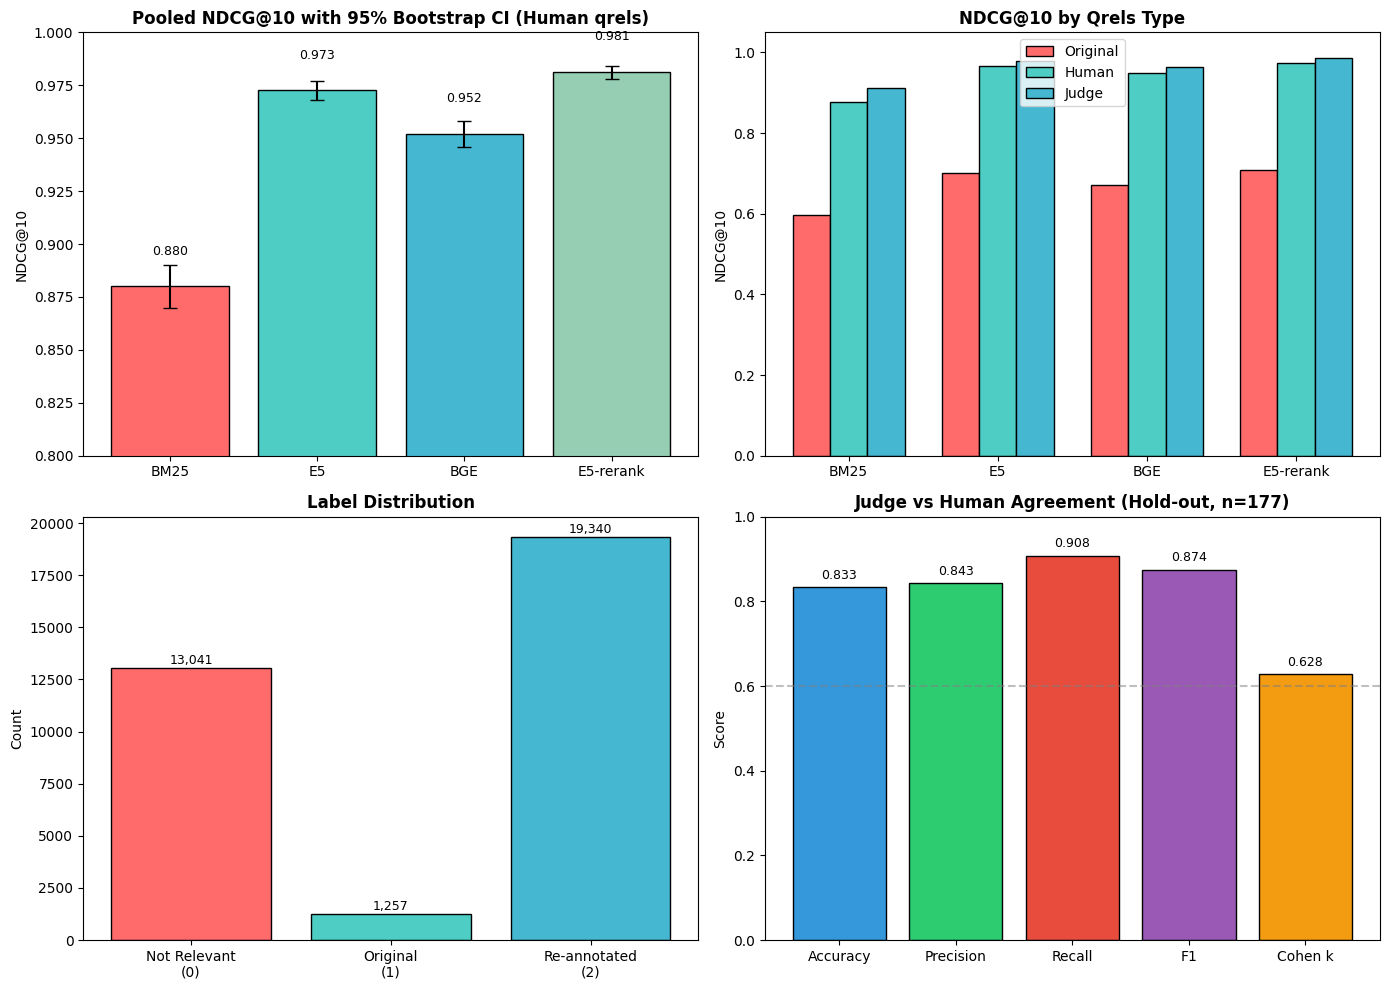

Сохранено: output_fixed/results_visualization.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. NDCG@10 с CI
ax1 = axes[0, 0]
models_display = ['BM25', 'E5', 'BGE', 'E5-rerank']
means = [bootstrap_ci_results[m]['mean'] for m in model_names]
lowers = [bootstrap_ci_results[m]['mean'] - bootstrap_ci_results[m]['lower'] for m in model_names]
uppers = [bootstrap_ci_results[m]['upper'] - bootstrap_ci_results[m]['mean'] for m in model_names]

colors = ['#ff6b6b', '#4ecdc4', '#45b7d1', '#96ceb4']
bars = ax1.bar(models_display, means, yerr=[lowers, uppers], color=colors, capsize=5, edgecolor='black')
ax1.set_ylabel('NDCG@10')
ax1.set_title('Pooled NDCG@10 with 95% Bootstrap CI (Human qrels)', fontweight='bold')
ax1.set_ylim(0.8, 1.0)
for bar, mean in zip(bars, means):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015, f'{mean:.3f}', 
             ha='center', fontsize=9)

# 2. Сравнение трёх типов qrels
ax2 = axes[0, 1]
x = np.arange(len(model_names))
width = 0.25

orig_vals = [ndcg_comparison[m]['Original']['NDCG@10']['mean'] for m in model_names]
human_vals = [ndcg_comparison[m]['Human']['NDCG@10']['mean'] for m in model_names]
judge_vals = [ndcg_comparison[m]['Judge']['NDCG@10']['mean'] for m in model_names]

ax2.bar(x - width, orig_vals, width, label='Original', color='#ff6b6b', edgecolor='black')
ax2.bar(x, human_vals, width, label='Human', color='#4ecdc4', edgecolor='black')
ax2.bar(x + width, judge_vals, width, label='Judge', color='#45b7d1', edgecolor='black')

ax2.set_ylabel('NDCG@10')
ax2.set_title('NDCG@10 by Qrels Type', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(models_display)
ax2.legend()
ax2.set_ylim(0, 1.05)

# 3. Распределение меток
ax3 = axes[1, 0]
labels = ['Not Relevant\n(0)', 'Original\n(1)', 'Re-annotated\n(2)']
values = [stats['label_0'], stats['label_1'], stats['label_2']]
colors3 = ['#ff6b6b', '#4ecdc4', '#45b7d1']
bars3 = ax3.bar(labels, values, color=colors3, edgecolor='black')
ax3.set_title('Label Distribution', fontweight='bold')
ax3.set_ylabel('Count')
for bar, val in zip(bars3, values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, f'{val:,}', 
             ha='center', fontsize=9)

# 4. Judge vs Human
ax4 = axes[1, 1]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'Cohen k']
values4 = [
    agreement['accuracy'],
    agreement['precision'],
    agreement['recall'],
    agreement['f1'],
    agreement['cohen_kappa']
]
colors4 = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f39c12']
bars4 = ax4.bar(metrics, values4, color=colors4, edgecolor='black')
ax4.set_ylabel('Score')
ax4.set_title(f'Judge vs Human Agreement (Hold-out, n={agreement["n_queries"]})', fontweight='bold')
ax4.set_ylim(0, 1.0)
ax4.axhline(y=0.6, color='gray', linestyle='--', alpha=0.5, label='Substantial agreement')

for bar, val in zip(bars4, values4):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(config.OUTPUT_DIR / 'results_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Сохранено: {config.OUTPUT_DIR / 'results_visualization.png'}")

## Дополнительные визуализации
Расширенные графики для статьи: калибровка судьи, выбор порога, дельты NDCG по запросам и пересечение qrels.


In [ ]:

from scipy.special import expit
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

scores = test_results['scores']
y_true = test_results['y_true']
probs = expit(scores)

# Calibration curve
prob_true, prob_pred = calibration_curve(y_true, probs, n_bins=10, strategy='uniform')

# Precision/Recall vs threshold
prec, rec, thresh = precision_recall_curve(y_true, scores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(prob_pred, prob_true, marker='o')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='идеальная калибровка')
axes[0].set_title('Калибровка судьи (test)')
axes[0].set_xlabel('Предсказанная вероятность')
axes[0].set_ylabel('Доля релевантных')
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend()

axes[1].plot(thresh, prec[:-1], label='Precision')
axes[1].plot(thresh, rec[:-1], label='Recall')
axes[1].axvline(optimal_threshold, color='red', linestyle='--', label=f'T*={optimal_threshold:.2f}')
axes[1].set_title('Precision/Recall vs threshold (test)')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Score')
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend()

plt.tight_layout()


In [ ]:

# ΔNDCG@10 per query (Human - Original)
model_query_orig = {m: get_per_query_ndcg(labeled_data, m, qrels_original, k=10) for m in model_names}
model_query_human = {m: get_per_query_ndcg(labeled_data, m, qrels_human, k=10) for m in model_names}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for ax, m in zip(axes, model_names):
    common_q = set(model_query_orig[m].keys()) & set(model_query_human[m].keys())
    deltas = [model_query_human[m][q] - model_query_orig[m][q] for q in common_q]
    ax.hist(deltas, bins=30, color='#4ecdc4', edgecolor='black', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--')
    ax.set_title(f'{m.upper()}: ΔNDCG@10 (Human - Original)')
    ax.set_xlabel('ΔNDCG@10')
    ax.set_ylabel('Частота')
plt.tight_layout()


In [ ]:

# Jaccard пересечение qrels
import itertools

def qrels_to_set(qrels):
    s = set()
    for qid, docs in qrels.items():
        for docid in docs.keys():
            s.add((qid, docid))
    return s

qrels_dict = {
    'Original': qrels_original,
    'Human': qrels_human,
    'Judge': qrels_judge,
}
sets = {k: qrels_to_set(v) for k, v in qrels_dict.items()}

labels = list(qrels_dict.keys())
matrix = []
for a in labels:
    row = []
    for b in labels:
        inter = len(sets[a] & sets[b])
        union = len(sets[a] | sets[b]) if len(sets[a] | sets[b])>0 else 1
        row.append(inter/union)
    matrix.append(row)

plt.figure(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt='.2f', xticklabels=labels, yticklabels=labels, cmap='Blues', vmin=0, vmax=1)
plt.title('Jaccard пересечение qrels')
plt.tight_layout()


---
## 12. Сохранение результатов

In [ ]:
all_results = {
    'stats': {
        'total_queries': stats['total_queries'],
        'total_docs': stats['total_docs'],
        'label_0': stats['label_0'],
        'label_1': stats['label_1'],
        'label_2': stats['label_2'],
    },
    'qrels_stats': {
        'original': {'relevant_pairs': orig_rel, 'queries': orig_q},
        'human': {'relevant_pairs': human_rel, 'queries': human_q},
        'judge': {'relevant_pairs': judge_rel, 'queries': judge_q}
    },
    'ndcg_comparison': ndcg_comparison,
    'ndcg_meta': {
        'type': 'pooled',
        'candidates_per_query': '~30-40',
        'note': 'NOT comparable to full-corpus leaderboard!'
    },
    'judge_vs_human_holdout': agreement,
    'bootstrap_ci': bootstrap_ci_results,
    'statistical_tests': {
        'all_pairwise_significant': all_significant,
        'n_permutations': config.N_PERMUTATIONS
    },
    'config': {
        'base_model': config.BASE_MODEL,
        'threshold': float(optimal_threshold),
        'threshold_source': 'validation_set'
    }
}

with open(config.OUTPUT_DIR / 'all_results.json', 'w') as f:
    json.dump(all_results, f, indent=2, ensure_ascii=False)

print(f"Результаты: {config.OUTPUT_DIR / 'all_results.json'}")

Результаты: output_fixed/all_results.json


---
## 13. Расширение на полный MS MARCO dev-set (6980 запросов)

Этот раздел:
1. Загружает полный MS MARCO dev-set
2. Генерирует run-файлы для BM25, E5, BGE через Pyserini
3. Применяет обученного судью ко всем запросам
4. Создает pseudo-qrels для полного dev-set

In [ ]:
# Установка дополнительных пакетов для MS MARCO
!pip install -q ir_datasets pyserini faiss-cpu


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip


# ========================================
# КОНФИГУРАЦИЯ MS MARCO EXTENSION
# ========================================
EXTEND_TO_FULL_MSMARCO = False  # <-- Установите True для расширения

MSMARCO_DIR = Path("msmarco_data")
MSMARCO_DIR.mkdir(exist_ok=True)

TOP_K_PER_MODEL = 100  # Сколько документов брать на запрос

print(f"EXTEND_TO_FULL_MSMARCO = {EXTEND_TO_FULL_MSMARCO}")
print(f"MS MARCO директория: {MSMARCO_DIR}")
print(f"TOP_K per model: {TOP_K_PER_MODEL}")
print("\nДля расширения на полный MS MARCO установите EXTEND_TO_FULL_MSMARCO = True")

In [ ]:
# Fallback in case variable not defined in this session
if "EXTEND_TO_FULL_MSMARCO" not in globals():
    EXTEND_TO_FULL_MSMARCO = False

if EXTEND_TO_FULL_MSMARCO:
    import ir_datasets
    
    print("Загрузка MS MARCO passage dev через ir_datasets...")
    dataset = ir_datasets.load("msmarco-passage/dev")
    
    # Загрузка запросов
    msmarco_queries = {}
    for query in dataset.queries_iter():
        msmarco_queries[query.query_id] = query.text
    print(f"Загружено {len(msmarco_queries)} запросов")
    
    # Загрузка документов
    print("Загрузка корпуса документов (это может занять время)...")
    corpus_dataset = ir_datasets.load("msmarco-passage")
    
    msmarco_corpus = {}
    for i, doc in enumerate(corpus_dataset.docs_iter()):
        msmarco_corpus[doc.doc_id] = doc.text
        if (i + 1) % 1000000 == 0:
            print(f"  Загружено {i+1:,} документов...")
    print(f"Загружено {len(msmarco_corpus):,} документов")
    
    # Загрузка оригинальных qrels
    msmarco_qrels_orig = {}
    for qrel in dataset.qrels_iter():
        if qrel.query_id not in msmarco_qrels_orig:
            msmarco_qrels_orig[qrel.query_id] = {}
        msmarco_qrels_orig[qrel.query_id][qrel.doc_id] = qrel.relevance
    print(f"Оригинальных qrels: {sum(len(v) for v in msmarco_qrels_orig.values())} пар")
else:
    print("Расширение на полный MS MARCO отключено.")
    print("Установите EXTEND_TO_FULL_MSMARCO = True для активации.")

Расширение на полный MS MARCO отключено.
Установите EXTEND_TO_FULL_MSMARCO = True для активации.


In [ ]:
pip install pyserini


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Fallback in case variable not defined in this session
if "EXTEND_TO_FULL_MSMARCO" not in globals():
    EXTEND_TO_FULL_MSMARCO = False

if EXTEND_TO_FULL_MSMARCO:
    # Импорт Pyserini с диагностикой ошибок установки
    try:
        from pyserini.search.lucene import LuceneSearcher
    except ModuleNotFoundError:
        import sys, subprocess
        print("Pyserini не найден. Диагностика...")
        # Проверим pip и версию Python
        print('Python:', sys.executable)
        subprocess.run([sys.executable, "-m", "pip", "--version"])
        # Обновим pip
        subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade", "pip"])
        # Установим зависимости по отдельности, чтобы увидеть ошибку
        for pkg in ["pyserini==0.22.1", "ir_datasets==0.5.11", "faiss-cpu"]:
            print(f"Устанавливаю {pkg} ...")
            res = subprocess.run([sys.executable, "-m", "pip", "install", pkg])
            if res.returncode != 0:
                print(f"Ошибка при установке {pkg}! См. вывод выше.")
        try:
            from pyserini.search.lucene import LuceneSearcher
            print("Pyserini установлен, продолжаю")
        except Exception as e:
            print(f"Pyserini всё ещё не импортируется: {e}")
            raise
    
    RUN_FILES_DIR = MSMARCO_DIR / "run_files"
    RUN_FILES_DIR.mkdir(exist_ok=True)
    
    msmarco_runs = {}
    query_ids = list(msmarco_queries.keys())
    query_texts = [msmarco_queries[qid] for qid in query_ids]
    
    # ========== BM25 с Pyserini ==========
    print("="*50)
    print("BM25 retrieval с Pyserini prebuilt index...")
    print("="*50)
    
    bm25_path = RUN_FILES_DIR / "bm25.run"
    if bm25_path.exists():
        print(f"  Файл {bm25_path} уже существует, загружаем...")
    else:
        try:
            searcher = LuceneSearcher.from_prebuilt_index('msmarco-v1-passage')
            print(f"  Индекс загружен: {searcher.num_docs:,} документов")
            
            with open(bm25_path, 'w') as f:
                for i, (qid, query) in enumerate(zip(query_ids, query_texts)):
                    hits = searcher.search(query, k=TOP_K_PER_MODEL)
                    for rank, hit in enumerate(hits):
                        f.write(f"{qid} Q0 {hit.docid} {rank+1} {hit.score:.6f} bm25\n")
                    if (i + 1) % 1000 == 0:
                        print(f"    Обработано {i+1}/{len(query_ids)} запросов")
            print(f"  Сохранено: {bm25_path}")
        except Exception as e:
            print(f"  Ошибка BM25: {e}")
    
    # Загрузка BM25 runs
    if bm25_path.exists():
        msmarco_runs['bm25'] = {}
        with open(bm25_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 6:
                    qid, _, docid, rank, score, _ = parts[:6]
                    if qid not in msmarco_runs['bm25']:
                        msmarco_runs['bm25'][qid] = []
                    if len(msmarco_runs['bm25'][qid]) < TOP_K_PER_MODEL:
                        msmarco_runs['bm25'][qid].append((docid, float(score)))
        print(f"  BM25 загружен: {len(msmarco_runs['bm25'])} запросов")
    
    print(f"Загружено run-файлов: {list(msmarco_runs.keys())}")
else:
    print("Пропущено (EXTEND_TO_FULL_MSMARCO=False)")


Пропущено (EXTEND_TO_FULL_MSMARCO=False)


In [ ]:
# Fallback in case variable not defined in this session
if "EXTEND_TO_FULL_MSMARCO" not in globals():
    EXTEND_TO_FULL_MSMARCO = False

if EXTEND_TO_FULL_MSMARCO:
    # ========== E5 и BGE с SentenceTransformer + FAISS ==========
    from sentence_transformers import SentenceTransformer
    import faiss
    
    dense_models = {
        'e5': 'intfloat/e5-small-v2',
        'bge': 'BAAI/bge-small-en-v1.5'
    }
    
    for model_name, model_path in dense_models.items():
        print(f"\n{'='*50}")
        print(f"{model_name.upper()} retrieval...")
        print(f"{'='*50}")
        
        run_path = RUN_FILES_DIR / f"{model_name}.run"
        if run_path.exists():
            print(f"  Файл {run_path} уже существует, загружаем...")
        else:
            try:
                print(f"  Загрузка модели {model_path}...")
                encoder = SentenceTransformer(model_path, device=device)
                
                # Кодирование корпуса
                embeddings_path = MSMARCO_DIR / f"{model_name}_corpus_embeddings.npy"
                corpus_ids_path = MSMARCO_DIR / "corpus_ids.json"
                
                if embeddings_path.exists() and corpus_ids_path.exists():
                    print("  Загрузка сохраненных embeddings...")
                    corpus_embeddings = np.load(str(embeddings_path))
                    with open(corpus_ids_path, 'r') as f:
                        corpus_ids = json.load(f)
                else:
                    print("  Кодирование корпуса...")
                    corpus_ids = list(msmarco_corpus.keys())
                    if model_name == 'e5':
                        corpus_texts = ['passage: ' + msmarco_corpus[did] for did in corpus_ids]
                    else:
                        corpus_texts = [msmarco_corpus[did] for did in corpus_ids]
                    
                    corpus_embeddings = encoder.encode(corpus_texts, show_progress_bar=True, 
                                                       convert_to_numpy=True, batch_size=512)
                    
                    np.save(str(embeddings_path), corpus_embeddings)
                    with open(corpus_ids_path, 'w') as f:
                        json.dump(corpus_ids, f)
                
                print(f"  Corpus embeddings: {corpus_embeddings.shape}")
                
                # FAISS
                print("  Создание FAISS индекса...")
                dim = corpus_embeddings.shape[1]
                index = faiss.IndexFlatIP(dim)
                faiss.normalize_L2(corpus_embeddings)
                index.add(corpus_embeddings)
                
                # Кодирование запросов
                print("  Кодирование запросов...")
                if model_name == 'e5':
                    query_texts_enc = ['query: ' + msmarco_queries[qid] for qid in query_ids]
                else:
                    query_texts_enc = [msmarco_queries[qid] for qid in query_ids]
                
                query_embeddings = encoder.encode(query_texts_enc, show_progress_bar=True, 
                                                  convert_to_numpy=True)
                faiss.normalize_L2(query_embeddings)
                
                # Поиск
                print("  Поиск...")
                scores, indices = index.search(query_embeddings, TOP_K_PER_MODEL)
                
                # Сохранение
                print("  Сохранение run-файла...")
                with open(run_path, 'w') as f:
                    for qi, qid in enumerate(query_ids):
                        for rank, (idx, score) in enumerate(zip(indices[qi], scores[qi])):
                            docid = corpus_ids[idx]
                            f.write(f"{qid} Q0 {docid} {rank+1} {score:.6f} {model_name}\n")
                
                print(f"  Сохранено: {run_path}")
                del encoder, corpus_embeddings, query_embeddings, index
                
            except Exception as e:
                print(f"  Ошибка {model_name}: {e}")
        
        # Загрузка runs
        if run_path.exists():
            msmarco_runs[model_name] = {}
            with open(run_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 6:
                        qid, _, docid, rank, score, _ = parts[:6]
                        if qid not in msmarco_runs[model_name]:
                            msmarco_runs[model_name][qid] = []
                        if len(msmarco_runs[model_name][qid]) < TOP_K_PER_MODEL:
                            msmarco_runs[model_name][qid].append((docid, float(score)))
            print(f"  {model_name.upper()} загружен: {len(msmarco_runs[model_name])} запросов")
    
    print(f"\n{'='*50}")
    print("ИТОГО RUN-ФАЙЛЫ:")
    print(f"{'='*50}")
    for model_name, runs in msmarco_runs.items():
        print(f"  {model_name.upper()}: {len(runs)} запросов")
else:
    print("Пропущено")

Пропущено


In [ ]:
if EXTEND_TO_FULL_MSMARCO and len(msmarco_runs) > 0:
    print("Применение судьи к полному MS MARCO dev-set...")
    
    from sentence_transformers import CrossEncoder
    if 'judge_model' in globals() and hasattr(judge_model, 'predict'):
        ce_model = judge_model
    elif 'model' in globals() and hasattr(model, 'predict'):
        ce_model = model
    else:
        ce_model = CrossEncoder(str(config.MODEL_DIR), device=device, max_length=config.MAX_LENGTH)
    
    # Собираем уникальные пары
    all_pairs_set = set()
    for model_name, runs in msmarco_runs.items():
        for qid, docs in runs.items():
            for docid, score in docs:
                all_pairs_set.add((qid, docid))
    
    print(f"Уникальных пар (query, doc): {len(all_pairs_set):,}")
    
    # Фильтруем валидные пары
    valid_pairs = [(qid, docid) for qid, docid in all_pairs_set if qid in msmarco_queries and docid in msmarco_corpus]
    print(f"Валидных пар (с текстом): {len(valid_pairs):,}")
    
    full_judge_predictions = {}
    batch_size = 256
    
    for i in tqdm(range(0, len(valid_pairs), batch_size), desc="Applying judge"):
        batch_pairs = valid_pairs[i:i+batch_size]
        texts = [(msmarco_queries[qid], msmarco_corpus[docid]) for qid, docid in batch_pairs]
        scores = ce_model.predict(texts, batch_size=batch_size, show_progress_bar=False)
        for (qid, docid), score in zip(batch_pairs, scores):
            if qid not in full_judge_predictions:
                full_judge_predictions[qid] = {}
            full_judge_predictions[qid][docid] = float(score)
    
    print(f"\nОбработано {len(full_judge_predictions)} запросов")
    print(f"Всего пар с оценками: {sum(len(v) for v in full_judge_predictions.values()):,}")
else:
    print("Пропущено (нет run-файлов или EXTEND_TO_FULL_MSMARCO=False)")


Пропущено (нет run-файлов или EXTEND_TO_FULL_MSMARCO=False)


In [ ]:
if EXTEND_TO_FULL_MSMARCO and 'full_judge_predictions' in dir() and len(full_judge_predictions) > 0:
    # Создание pseudo-qrels
    full_pseudo_qrels = {}
    for qid, docs in full_judge_predictions.items():
        full_pseudo_qrels[qid] = {}
        for docid, score in docs.items():
            if score >= optimal_threshold:
                full_pseudo_qrels[qid][docid] = 1
    
    total_rel = sum(len(v) for v in full_pseudo_qrels.values())
    queries_with_rel = sum(1 for v in full_pseudo_qrels.values() if len(v) > 0)
    
    print("=" * 50)
    print("PSEUDO-QRELS ДЛЯ ПОЛНОГО MS MARCO")
    print("=" * 50)
    print(f"Запросов: {len(full_pseudo_qrels)}")
    print(f"Запросов с релевантными: {queries_with_rel}")
    print(f"Всего релевантных пар: {total_rel:,}")
    print(f"Avg релевантных/запрос: {total_rel/max(queries_with_rel,1):.2f}")
    
    # Сохранение
    OUTPUT_FULL = config.OUTPUT_DIR / "msmarco_full"
    OUTPUT_FULL.mkdir(exist_ok=True)
    
    with open(OUTPUT_FULL / 'pseudo_qrels_full.json', 'w') as f:
        json.dump(full_pseudo_qrels, f)
    
    with open(OUTPUT_FULL / 'pseudo_qrels_full.tsv', 'w') as f:
        f.write("query-id\tcorpus-id\tscore\n")
        for qid, docs in full_pseudo_qrels.items():
            for docid, rel in docs.items():
                f.write(f"{qid}\t{docid}\t{rel}\n")
    
    with open(OUTPUT_FULL / 'judge_scores_full.json', 'w') as f:
        json.dump(full_judge_predictions, f)
    
    print(f"\nСохранено в {OUTPUT_FULL}:")
    print(f"  - pseudo_qrels_full.json/tsv")
    print(f"  - judge_scores_full.json")
else:
    print("Pseudo-qrels для полного MS MARCO не созданы")

Pseudo-qrels для полного MS MARCO не созданы


In [ ]:

# Triplet-style scoring: [query + gold] vs candidate
gold_missing = 0
pairs = []
pair_info = []
for qid, qinfo in labeled_data.items():
    gold_texts = [d['text'] for d in qinfo['documents'].values() if d.get('true relevant', 0) in [1, 2]]
    if not gold_texts:
        gold_missing += 1
        continue
    gold_text = gold_texts[0]  # берем первый релевантный
    query_text = qinfo['query_text']
    for docid, dinfo in qinfo['documents'].items():
        cand_text = dinfo['text']
        pairs.append((f"{query_text} [SEP] {gold_text}", cand_text))
        pair_info.append((qid, docid))

print(f"Triplet scoring pairs: {len(pairs):,} (пропущено запросов без gold: {gold_missing})")

triplet_scores = {}
batch_size = 128
for i in range(0, len(pairs), batch_size):
    batch = pairs[i:i+batch_size]
    scores = model.predict(batch, batch_size=batch_size, show_progress_bar=False)
    for (qid, docid), score in zip(pair_info[i:i+batch_size], scores):
        triplet_scores.setdefault(qid, {})[docid] = float(score)


## Визуализации для тройкового подхода
Анализ ранжирования в триплет-сценарии: маржа между релевантными и нерелевантными, ранг лучшего релевантного и распределение скоров.


In [ ]:

# Подготовка данных для triplet-анализов
import numpy as np
import pandas as pd

triplet_rows = []
for qid, docdict in triplet_scores.items():
    for docid, score in docdict.items():
        dinfo = labeled_data[qid]['documents'].get(docid, {})
        label = dinfo.get('true relevant', 0)
        rel = 1 if label in [1, 2] else 0
        triplet_rows.append((qid, docid, score, rel))

df_triplet = pd.DataFrame(triplet_rows, columns=['qid', 'docid', 'score', 'rel'])
print(f"Triplet-анализ: {len(df_triplet)} пар, {df_triplet['qid'].nunique()} запросов")


In [ ]:

# Маржа score(pos) - score(neg) по запросам
margins = []
for qid, group in df_triplet.groupby('qid'):
    pos = group[group['rel']==1]['score']
    neg = group[group['rel']==0]['score']
    if len(pos)==0 or len(neg)==0:
        continue
    margins.append(pos.max() - neg.max())

plt.figure(figsize=(6,4))
plt.hist(margins, bins=30, color='#4ecdc4', edgecolor='black', alpha=0.8)
plt.axvline(np.mean(margins), color='red', linestyle='--', label=f"mean={np.mean(margins):.2f}")
plt.title('Маржа score(pos) - score(neg) по запросам')
plt.xlabel('Маржа')
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()


In [ ]:

# Ранг лучшего релевантного документа в каждом запросе
best_ranks = []
for qid, group in df_triplet.groupby('qid'):
    pos = group[group['rel']==1]
    if len(pos)==0:
        continue
    best_pos_score = pos['score'].max()
    rank = 1 + (group['score'] > best_pos_score).sum()
    best_ranks.append(rank)

plt.figure(figsize=(6,4))
plt.hist(best_ranks, bins=range(1, 12), color='#45b7d1', edgecolor='black', align='left', rwidth=0.8)
plt.title('Ранг лучшего релевантного (меньше = лучше)')
plt.xlabel('Ранг')
plt.ylabel('Частота запросов')
plt.xticks(range(1,11))
plt.tight_layout()


In [ ]:

# Распределение скоров: положительные vs отрицательные
plt.figure(figsize=(5,4))
plt.boxplot([
    df_triplet[df_triplet['rel']==1]['score'],
    df_triplet[df_triplet['rel']==0]['score']
], labels=['Положительные','Отрицательные'], showfliers=False)
plt.title('Распределение скоров (triplet view)')
plt.ylabel('Score')
plt.tight_layout()


---
## 14. Финальная сводка

In [ ]:
print("=" * 70)
print("ФИНАЛЬНАЯ СВОДКА")
print("=" * 70)

print(f"""
ДАННЫЕ:
  Запросов: {stats['total_queries']}
  Релевантных до:  {stats['label_1']} (avg {np.mean(stats['relevant_per_query_orig']):.2f}/query)
  Релевантных после: {stats['label_1'] + stats['label_2']} (avg {np.mean(stats['relevant_per_query_new']):.2f}/query)

СУДЬЯ:
  Модель: {config.BASE_MODEL}
  Threshold: {optimal_threshold:.4f}
  Test AUC: {test_results['auc']:.4f}
  Test F1: {test_results['f1']:.4f}

JUDGE VS HUMAN (hold-out):
  Accuracy: {agreement['accuracy']:.4f}
  Cohen's Kappa: {agreement['cohen_kappa']:.4f} ({agreement['kappa_interpretation']})

POOLED NDCG@10 (Human qrels):
  BM25:      {ndcg_comparison['bm25']['Human']['NDCG@10']['mean']:.4f}
  E5:        {ndcg_comparison['e5']['Human']['NDCG@10']['mean']:.4f}
  BGE:       {ndcg_comparison['bge']['Human']['NDCG@10']['mean']:.4f}
  E5-rerank: {ndcg_comparison['e5-rerank']['Human']['NDCG@10']['mean']:.4f}

ФАЙЛЫ:
""")

for f in sorted(config.OUTPUT_DIR.iterdir()):
    print(f"  - {f.name}")

ФИНАЛЬНАЯ СВОДКА

ДАННЫЕ:
  Запросов: 1179
  Релевантных до:  1257 (avg 1.07/query)
  Релевантных после: 20597 (avg 17.47/query)

СУДЬЯ:
  Модель: cross-encoder/ms-marco-MiniLM-L-6-v2
  Threshold: -0.9440
  Test AUC: 0.9057
  Test F1: 0.8745

JUDGE VS HUMAN (hold-out):
  Accuracy: 0.8335
  Cohen's Kappa: 0.6281 (Substantial)

POOLED NDCG@10 (Human qrels):
  BM25:      0.8771
  E5:        0.9672
  BGE:       0.9480
  E5-rerank: 0.9751

ФАЙЛЫ:

  - all_results.json
  - data_statistics.png
  - human_qrels_extended.json
  - human_qrels_extended.tsv
  - judge_config.json
  - judge_scores_raw.json
  - judge_scores_raw.tsv
  - msmarco_final.backup.ipynb
  - paper_tables_fixed.tex
  - pseudo_qrels_judge.json
  - pseudo_qrels_judge.tsv
  - results_visualization.png


---
## Готово!

### Результаты для 1179 запросов (с human-разметкой):
- `output_fixed/` - все результаты

### Для расширения на полный MS MARCO (6980 запросов):
1. Установите `EXTEND_TO_FULL_MSMARCO = True` в секции 13
2. Перезапустите ячейки раздела 13
3. Результаты будут в `output_fixed/msmarco_full/`

### Run-файлы:
| Модель | Метод |
|--------|-------|
| BM25 | Pyserini prebuilt index |
| E5 | SentenceTransformer + FAISS |
| BGE | SentenceTransformer + FAISS |